# Earth's companions: a quasi-satellite and a mini-moon

**The question.** The Moon is not the only thing that keeps Earth company. Two small asteroids
show two very different ways of doing it:

* **(469219) Kamoʻoalewa** (2016 HO3), a body a few tens of metres across, is Earth's best-known *quasi-satellite*.
  Its orbit around the Sun has almost exactly Earth's period, so seen from Earth it seems to
  circle us once a year, although it never comes within ~40 lunar distances and is never bound
  to Earth. De la Fuente Marcos & de la Fuente Marcos (2016, MNRAS 462, 3441) found that the
  present quasi-satellite episode began about 100 years ago and will end in about 300 years.
  Its reflectance spectrum looks like lunar rock (Sharkey et al. 2021, *Commun. Earth Environ.*
  2, 231), and it is the target of China's Tianwen-2 sample-return mission, launched in May 2025.
  It is small enough that sunlight measurably pushes it along its orbit: the **Yarkovsky effect**
  (Fenucci & Novaković 2021, AJ 162, 227; Fenucci et al. 2025, A&A 695, A196).
* **2024 PT5**, a body roughly 10 m across, was a *mini-moon*. Its energy relative to Earth was
  negative, so a two-body calculation would call it bound to Earth, from **2024 September 29 to
  November 25** (de la Fuente Marcos & de la Fuente Marcos 2024, RNAAS 8, 224). Its spectrum also
  points to the Moon as its source (Kareta et al. 2025, ApJL 979, L8).

What PyRoOrb does here: it fits both orbits from the MPC's astrometry. For Kamoʻoalewa it lets
the fit decide whether a Yarkovsky term earns its place (`nongrav="auto"`). It then propagates
both orbits, puts them in the Sun-Earth rotating frame, and tests the published claims:
* the quasi-satellite loop and the dates of the current episode;
* the Yarkovsky drift;
* 2024 PT5's capture dates.

Every number is checked against JPL (SBDB, Horizons, the close-approach database) or the papers.

**Frames and time scales.** `pyroorb.propagate` and `pyroorb.body_states` return heliocentric
states on ICRF (equatorial) axes, in au and au/day, at the times given. Here the times are always
astropy `Time` objects in **TDB**. For the rotating frame we rotate to the **J2000 ecliptic**
(obliquity 23.43928111°). Dates printed for people are **UTC**.

In [1]:
import json, urllib.request, urllib.parse, warnings
import numpy as np
import matplotlib.pyplot as plt
from astropy.time import Time
import pyroorb

pyroorb.load_settings()       # the .env settings file (data folders), before the first fit

# Future UTC dates make astropy warn that leap seconds are not yet known; harmless here.
warnings.filterwarnings("ignore", message=".*dubious year.*")
plt.rcParams.update({"figure.figsize": (8, 4.5), "figure.dpi": 110, "axes.grid": True,
                     "grid.alpha": 0.3})
print("PyRoOrb", pyroorb.__version__)

PyRoOrb 0.9.1


## 1. Fit both orbits from the astrometry

`nongrav="auto"` (the default) fits a gravity-only orbit first. A near-Earth asteroid with
perihelion inside 1.4 au is then offered a transverse Yarkovsky acceleration
$A_2\,(1\,\mathrm{au}/r)^2$, which is kept only if it pays for itself under an information
criterion. Neither object has radar astrometry.

In [2]:
def tdb(jd):
    return Time(jd, format="jd", scale="tdb")

def utc(jd_tdb):
    return tdb(jd_tdb).utc.iso[:16]

obs_k = pyroorb.fetch_observations("469219")
kamo = pyroorb.fit_orbit(obs_k, designation="469219")
obs_p = pyroorb.fetch_observations("2024 PT5")
pt5 = pyroorb.fit_orbit(obs_p, designation="2024 PT5")

for name, f in [("Kamoʻoalewa", kamo), ("2024 PT5", pt5)]:
    print(f"{name:12s} {f.n_observations():4d} of {f.n_total_observations()} obs, "
          f"arc {f.arc_length_days() / 365.25:5.1f} yr, rms {f.rms_residual():.2f}\", "
          f"epoch {f.epoch_iso()[:10]} TDB, non-grav: {f.nongrav_model or 'none'} {f.nongrav_params}")

Kamoʻoalewa   334 of 335 obs, arc  21.0 yr, rms 0.16", epoch 2016-04-27 TDB, non-grav: yarkovsky {'A2': -1.3430586570499158e-13}
2024 PT5      402 of 410 obs, arc   0.5 yr, rms 0.45", epoch 2024-08-23 TDB, non-grav: none {}


Kamoʻoalewa has observations going back to 2004 (Sloan Digital Sky Survey precoveries). Over
those 21 years the fit chose a Yarkovsky term. 2024 PT5 was found in August 2024, and its arc
is only half a year long. It stays gravity-only.

## 2. Kamoʻoalewa's Yarkovsky drift

How much does $A_2$ buy? Refit the same observations gravity-only and compare. Then compare $A_2$
with JPL's value, read live from the Small-Body Database (SBDB). JPL uses the same
$1/r^2$ transverse model.

In [3]:
kamo_grav = pyroorb.fit_orbit(obs_k, designation="469219", nongrav="none")
print(f"gravity only : rms {kamo_grav.rms_residual():.3f}\"  {kamo_grav.n_excluded()} obs rejected")
print(f"with A2      : rms {kamo.rms_residual():.3f}\"  {kamo.n_excluded()} obs rejected")

def sbdb(desig):
    q = urllib.parse.urlencode({"sstr": desig, "full-prec": "true"})
    return json.load(urllib.request.urlopen("https://ssd-api.jpl.nasa.gov/sbdb.api?" + q,
                                            timeout=60))["orbit"]

jpl_k = sbdb("469219")
jpl_a2 = {p["name"]: p for p in jpl_k["model_pars"]}["A2"]
A2 = kamo.nongrav_params["A2"]
minus, plus = kamo.rational_nongrav_intervals()["A2"]
print(f"\nA2 PyRoOrb : {A2:.3e} au/d^2  (-{minus:.2e} / +{plus:.2e}, profile-likelihood 1-sigma)")
print(f"A2 JPL     : {float(jpl_a2['value']):.3e} au/d^2  (+/- {float(jpl_a2['sigma']):.2e}), "
      f"solution of {jpl_k['soln_date'][:10]}, {jpl_k['n_obs_used']} obs")
print(f"difference : {(A2 - float(jpl_a2['value'])) / float(jpl_a2['sigma']):+.2f} JPL sigma")

gravity only : rms 0.213"  5 obs rejected
with A2      : rms 0.163"  1 obs rejected



A2 PyRoOrb : -1.343e-13 au/d^2  (-1.29e-14 / +1.26e-14, profile-likelihood 1-sigma)
A2 JPL     : -1.341e-13 au/d^2  (+/- 1.77e-14), solution of 2026-09-03, 335 obs
difference : -0.01 JPL sigma


The Yarkovsky term lowers the RMS by about a quarter and lets the fit keep a few more
observations. The fitted $A_2$ is negative: the asteroid is slowly spiralling *inward*, which
means it rotates retrograde. PyRoOrb's value matches JPL's to within a small fraction of the
uncertainty. That is no surprise: both are fitted to the same MPC astrometry with the same
force model.

A more physical number is the drift in semi-major axis. For a transverse acceleration
$A_2 (r_0/r)^2$, averaging Gauss's equation over one orbit gives
$\langle \dot a\rangle = 2A_2 r_0^2 / \left(n a^2 (1-e^2)\right)$. Fenucci et al. (2025,
A&A 695, A196) fitted Kamoʻoalewa's orbit with new 2024 astrometry and a remeasured 2004 SDSS
precovery and give $\dot a = (-67.35 \pm 4.70)\times10^{-4}$ au/Myr.

In [4]:
el = kamo.elements()
n = np.radians(el["n"])                                         # rad/day
def dadt(a2):                                                   # au/day^2 -> au/Myr
    return 2 * a2 / (n * el["a"] ** 2 * (1 - el["e"] ** 2)) * 365.25e6
sig = max(minus, plus)
print(f"da/dt PyRoOrb          : ({dadt(A2) * 1e4:.1f} +/- {abs(dadt(sig)) * 1e4:.1f}) x 1e-4 au/Myr")
print(f"da/dt Fenucci+ 2025    : (-67.35 +/- 4.70) x 1e-4 au/Myr")
print(f"difference             : {(dadt(A2) * 1e4 + 67.35) / np.hypot(4.70, abs(dadt(sig)) * 1e4):.1f} "
      f"combined sigma")
print(f"semi-major axis change over 300 yr: {dadt(A2) * 300e-6 * 1.496e8:+.0f} km")

da/dt PyRoOrb          : (-57.6 +/- 5.5) x 1e-4 au/Myr
da/dt Fenucci+ 2025    : (-67.35 +/- 4.70) x 1e-4 au/Myr
difference             : 1.3 combined sigma
semi-major axis change over 300 yr: -259 km


Our drift is weaker than Fenucci et al.'s by about 1.3 combined standard deviations.
Some tension, but not a contradiction. The two fits use different data: theirs adds their own
2024 Loiano and Calar Alto astrometry and a remeasured 2004 precovery, with their own weights,
and our MPC download need not contain the same positions. JPL's fit uses the same astrometry as
ours and agrees with it, which suggests the difference lies in the data and the weights, not
the model.

The drift is real, but tiny: a few hundred km in semi-major axis over three centuries. Section 4
asks whether that matters for the quasi-satellite.

## 3. Check both orbits against JPL

**Elements.** JPL's SBDB gives osculating heliocentric elements (J2000 ecliptic) at its own
epoch. We propagate each PyRoOrb orbit to that epoch (`propagate` → `osculating_elements`) and
compare. The differences are given in units of JPL's 1σ and of ours. Our σ at that epoch comes from
300 orbits drawn from our fit's covariance, each propagated to the epoch.

In [5]:
jpl_p = sbdb("2024 PT5")
names = {"e": "e", "a": "a", "i": "i", "om": "asc_node", "w": "arg_per", "ma": "M"}
for label, f, jpl in [("Kamoʻoalewa", kamo, jpl_k), ("2024 PT5", pt5, jpl_p)]:
    ep = float(jpl["epoch"])
    ours = pyroorb.osculating_elements(pyroorb.propagate(f, tdb(ep))[0], tdb(ep))
    cloud = pyroorb.sample_orbits(f, 300, rng_seed=3).propagate(tdb(ep))[0]          # (300, 6)
    cloud_el = [pyroorb.osculating_elements(x, tdb(ep)) for x in cloud]
    print(f"{label}: JPL solution {jpl['soln_date'][:10]}, epoch JD {ep} TDB")
    print(f"   {'':5s}{'PyRoOrb':>16s}{'JPL':>16s}{'diff':>12s}{'/ JPL sigma':>13s}{'/ our sigma':>13s}")
    for e in jpl["elements"]:
        if e["name"] in names:
            key = names[e["name"]]
            ours_v, jv, js = ours[key], float(e["value"]), float(e["sigma"])
            our_sig = np.std([c[key] for c in cloud_el])
            print(f"   {e['name']:5s}{ours_v:16.9f}{jv:16.9f}{ours_v - jv:12.2e}"
                  f"{(ours_v - jv) / js:13.1f}{(ours_v - jv) / our_sig:13.1f}")

Kamoʻoalewa: JPL solution 2026-09-03, epoch JD 2461200.5 TDB
                 PyRoOrb             JPL        diff  / JPL sigma  / our sigma
   e         0.102238863     0.102238843    2.00e-08          0.1          0.1
   a         1.000810464     1.000810462    2.16e-09          0.3          0.3
   i         7.802616952     7.802614369    2.58e-06          0.2          0.2
   om       65.593173699    65.593241995   -6.83e-05         -5.6         -4.1
   w       304.363254740   304.363212786    4.20e-05          1.7          1.4
   ma      243.387172861   243.387144233    2.86e-05          0.8          0.8
2024 PT5: JPL solution 2025-02-06, epoch JD 2461200.5 TDB
                 PyRoOrb             JPL        diff  / JPL sigma  / our sigma
   e         0.015273643     0.015273652   -9.29e-09         -0.6         -0.8
   a         1.022167110     1.022167113   -2.40e-09         -0.2         -0.3
   i         1.713428453     1.713425381    3.07e-06          8.4         12.2
   om      2

The size and shape (a, e) and the position along the orbit (M) agree within one σ. The
orientation of the orbital plane does not. Kamoʻoalewa's node differs by about 4-6σ. For
2024 PT5, the node and inclination differ by 8-13 of JPL's σ and 12-23 of ours (PyRoOrb's σ
for this orbit are a little *smaller* than JPL's).

In absolute terms the differences are small. For a plane inclined by $i$, a node shift
$\Delta\Omega$ tilts the plane by about $\Delta\Omega \sin i$. Combined with $\Delta i$,
the two solutions' planes differ by $1.7\times10^{-7}$ rad for both objects, which is about
25 km out of the plane at 1 au. Still, for 2024 PT5 that is a real disagreement between two
solutions, larger than either code's formal uncertainty. The most likely cause is the data:
JPL keeps 380 observations and PyRoOrb 402, and each weights them its own way. For an object
observed while moving across the sky at degrees per day, small station or timing errors can
leave a systematic offset that formal σ do not include. We have not tracked it down further.
The distance checks below show that it barely affects where the object is seen from Earth.

**Distances from Earth.** Horizons gives JPL's geocentric state on any date. We compare the
geometric Earth-to-object distance (no light-time correction, both in TDB) at a few dates:
Kamoʻoalewa's first observation, its discovery, Tianwen-2's arrival (July 2026), and a date 30
years past the data; and 2024 PT5's August 2024 flyby, the middle of its capture, and its 2055
return. Our 1σ comes from the fit's covariance, propagated linearly
(`propagate(..., covariance=True)`).

In [6]:
AU_KM = 1.495978707e8
LD_KM = 384_400.0                    # mean Earth-Moon distance

def horizons_geocentric(command, jd_tdb):
    q = {"format": "json", "COMMAND": f"'{command}'", "EPHEM_TYPE": "VECTORS", "CENTER": "'500@399'",
         "TLIST": " ".join(f"'{j}'" for j in jd_tdb), "TIME_TYPE": "TDB", "VEC_TABLE": "2",
         "REF_PLANE": "FRAME", "OUT_UNITS": "AU-D", "CSV_FORMAT": "YES"}
    res = json.load(urllib.request.urlopen("https://ssd.jpl.nasa.gov/api/horizons.api?"
                                           + urllib.parse.urlencode(q), timeout=60))["result"]
    rows = res.split("$$SOE")[1].split("$$EOE")[0].strip().splitlines()
    return np.array([[float(v) for v in r.split(",")[2:8]] for r in rows])

def geocentric_check(label, f, command, dates):
    jd = np.array([Time(d).tdb.jd for d in dates])
    X, C = pyroorb.propagate(f, tdb(jd), covariance=True)
    g = X[:, :3] - pyroorb.body_states("earth", tdb(jd))[:, :3]
    d = np.linalg.norm(g, axis=1)
    u = g / d[:, None]
    sig = np.sqrt(np.einsum("ni,nij,nj->n", u, C[:, :3, :3], u))
    dj = np.linalg.norm(horizons_geocentric(command, jd)[:, :3], axis=1)
    print(f"{label}\n   {'date (UTC)':12s}{'PyRoOrb km':>15s}{'JPL km':>15s}{'diff km':>10s}{'our 1-sigma':>13s}{'LD':>7s}")
    for date, a, b, s in zip(dates, d * AU_KM, dj * AU_KM, sig * AU_KM):
        print(f"   {date:12s}{a:15,.0f}{b:15,.0f}{a - b:10.1f}{s:13.1f}{a / LD_KM:7.1f}")

geocentric_check("Kamoʻoalewa", kamo, "469219;",
                 ["2004-03-17", "2016-04-27", "2026-07-01", "2056-01-01"])
geocentric_check("2024 PT5", pt5, "DES=2024 PT5;",
                 ["2024-08-08", "2024-10-27", "2025-01-09", "2055-11-08"])

Kamoʻoalewa
   date (UTC)       PyRoOrb km         JPL km   diff km  our 1-sigma     LD
   2004-03-17       28,373,373     28,373,381      -7.9         61.8   73.8
   2016-04-27       19,994,259     19,994,261      -1.9         37.9   52.0
   2026-07-01       41,448,192     41,448,188       3.6        107.8  107.8
   2056-01-01       38,312,681     38,312,655      26.3        249.1   99.7


2024 PT5
   date (UTC)       PyRoOrb km         JPL km   diff km  our 1-sigma     LD
   2024-08-08          572,326        572,326       0.1          0.3    1.5
   2024-10-27        4,029,879      4,029,880      -0.1          0.5   10.5
   2025-01-09        1,800,583      1,800,583       0.0          0.9    4.7
   2055-11-08        5,352,462      5,352,471      -9.1         27.3   13.9


Inside the observed arcs the two codes agree to within 10 km for Kamoʻoalewa (at 20-40 million km)
and a fraction of a km for 2024 PT5. Far beyond the data (Kamoʻoalewa in 2056, 2024 PT5 in 2055), the differences
grow, but they stay comparable to our own linear 1σ. JPL's numbers are not the truth here.
They come from another fit to nearly the same data, so a difference of about 1σ is what to
expect.

## 4. The quasi-satellite loop

In the frame that rotates with Earth around the Sun (Earth fixed on the +x axis, the Sun at
x = −1 au), a co-orbital with Earth's period and a slightly eccentric, inclined orbit traces
a loop once a year. Kamoʻoalewa's eccentricity of 0.10 against Earth's 0.017 makes the loop
about 0.1 au deep along the Sun-Earth line. The loop is centred on Earth, so the asteroid seems
to circle us, but the circling is a geometric effect: what holds it there is the Sun.

The rotating frame: rotate each heliocentric state to the J2000 ecliptic, then turn about the
ecliptic pole by Earth's instantaneous heliocentric longitude, and finally shift the origin to
Earth.

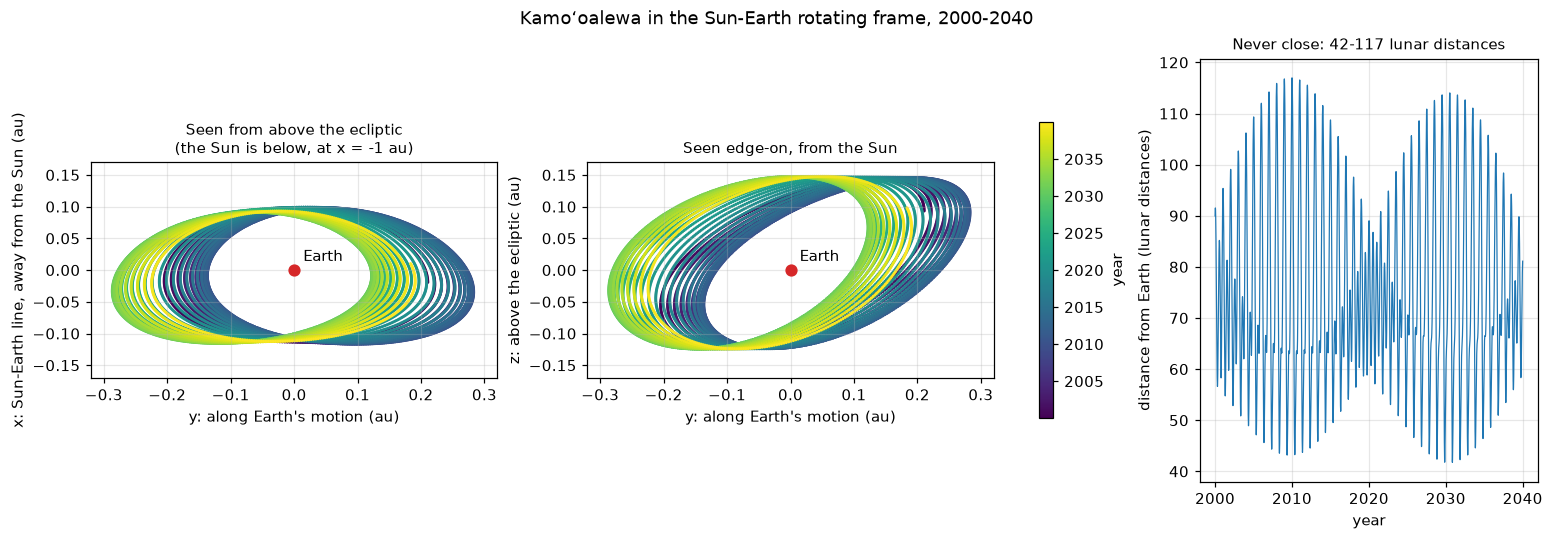

2000-2040: 42 to 117 lunar distances (0.107-0.301 au)


In [7]:
EPS = np.radians(23.43928111)                       # J2000 mean obliquity
_c, _s = np.cos(EPS), np.sin(EPS)
EQ_TO_ECL = np.array([[1, 0, 0], [0, _c, _s], [0, -_s, _c]])

def rotating(states, earth):
    # Ecliptic positions in the Sun-Earth rotating frame: Earth at the origin, +x pointing
    # away from the Sun along the Sun-Earth line, +y along Earth's motion, z to the ecliptic pole.
    r, e = states[:, :3] @ EQ_TO_ECL.T, earth[:, :3] @ EQ_TO_ECL.T
    lon = np.arctan2(e[:, 1], e[:, 0])
    c, s = np.cos(lon), np.sin(lon)
    x, y = c * r[:, 0] + s * r[:, 1], -s * r[:, 0] + c * r[:, 1]
    return np.column_stack([x - np.hypot(e[:, 0], e[:, 1]), y, r[:, 2] - e[:, 2]])

jd = Time("2000-01-01").tdb.jd + np.arange(0, 40 * 365.25, 1.0)        # 2000-2040, daily
K = pyroorb.propagate(kamo, tdb(jd))
E = pyroorb.body_states("earth", tdb(jd))
R = rotating(K, E)
dist = np.linalg.norm(K[:, :3] - E[:, :3], axis=1)
yr = 2000 + (jd - 2451544.5) / 365.25

fig, ax = plt.subplots(1, 3, figsize=(14, 4.8), layout="constrained",
                       gridspec_kw={"width_ratios": [1.2, 1.2, 1]})
for axis, (i, j, lab) in zip(ax[:2], [(1, 0, "x: Sun-Earth line, away from the Sun (au)"),
                                       (1, 2, "z: above the ecliptic (au)")]):
    sc = axis.scatter(R[:, i], R[:, j], c=yr, s=1, cmap="viridis")
    axis.plot(0, 0, "o", color="C3", ms=7)
    axis.annotate("Earth", (0, 0), xytext=(6, 6), textcoords="offset points")
    axis.set_aspect("equal"); axis.set_xlim(-0.32, 0.32); axis.set_ylim(-0.17, 0.17)
    axis.set_xlabel("y: along Earth's motion (au)"); axis.set_ylabel(lab)
ax[0].set_title("Seen from above the ecliptic\n(the Sun is below, at x = -1 au)", fontsize=10)
ax[1].set_title("Seen edge-on, from the Sun", fontsize=10)
fig.colorbar(sc, ax=ax[:2], label="year", shrink=0.7)
ax[2].plot(yr, dist * AU_KM / LD_KM, lw=0.8)
ax[2].set_xlabel("year"); ax[2].set_ylabel("distance from Earth (lunar distances)")
ax[2].set_title(f"Never close: {dist.min() * AU_KM / LD_KM:.0f}-{dist.max() * AU_KM / LD_KM:.0f} lunar distances",
                fontsize=10)
fig.suptitle("Kamoʻoalewa in the Sun-Earth rotating frame, 2000-2040")
plt.show()
print(f"2000-2040: {dist.min() * AU_KM / LD_KM:.0f} to {dist.max() * AU_KM / LD_KM:.0f} lunar distances "
      f"({dist.min():.3f}-{dist.max():.3f} au)")

Seen from above, the yearly loop is an oval about 0.55 au long, and it drifts slowly to and fro
along Earth's orbit. Seen edge-on, it is a loop in the vertical plane: the 7.8° inclination
carries the asteroid about 0.12 au above and below the ecliptic each year, so Earth sits
inside a tilted ring, not a flat one. Kamoʻoalewa never comes closer than about 40 lunar distances (0.1 au), ten times
Earth's Hill radius (about 0.01 au), the distance inside which Earth's gravity beats the Sun's
tide. This is why a quasi-satellite is a companion and not a moon.

## 5. Centuries: the episode begins and ends

The yearly loop is the fast motion. The slow motion, the *guiding centre*, shows in the
relative **mean longitude** $\lambda_r = \lambda - \lambda_\oplus$, with
$\lambda = \Omega + \omega + M$ for each body (osculating, heliocentric, ecliptic). In
a quasi-satellite state $\lambda_r$ librates about **0°** (the guiding centre stays on Earth).
In a *horseshoe* state it swings in a wide arc through 180° and turns back on either side of
Earth without crossing 0°.

We propagate from 1600 to 2600, close to the limit of the DE440 ephemeris file PyRoOrb
integrates in (1550-2650; `propagate` refuses times outside it). The mean longitude is computed
for all 73,000 states at once with a small numpy function, checked first against
`pyroorb.osculating_elements`.

In [8]:
MU_SUN = 0.01720209895 ** 2                         # au^3/day^2 (Gaussian constant)

def mean_longitude(X):
    # Heliocentric osculating mean longitude Omega + omega + M (radians), ecliptic J2000.
    r, v = X[..., :3] @ EQ_TO_ECL.T, X[..., 3:] @ EQ_TO_ECL.T
    rn = np.linalg.norm(r, axis=-1)
    h = np.cross(r, v)
    node = np.arctan2(h[..., 0], -h[..., 1])
    inc = np.arccos(h[..., 2] / np.linalg.norm(h, axis=-1))
    a = 1 / (2 / rn - (v ** 2).sum(-1) / MU_SUN)
    ecosE, esinE = 1 - rn / a, (r * v).sum(-1) / np.sqrt(MU_SUN * a)
    e, ecc_anom = np.hypot(ecosE, esinE), np.arctan2(esinE, ecosE)
    true_anom = np.arctan2(np.sqrt(1 - e ** 2) * np.sin(ecc_anom), np.cos(ecc_anom) - e)
    arg_lat = np.arctan2(r[..., 2] / np.sin(inc), r[..., 0] * np.cos(node) + r[..., 1] * np.sin(node))
    return node + arg_lat - true_anom + (ecc_anom - esinE)

el_now = pyroorb.osculating_elements(K[0], tdb(jd[0]))
print(f"check, 2000-01-01: numpy {np.degrees(mean_longitude(K[0])) % 360:.9f} deg, "
      f"osculating_elements {(el_now['asc_node'] + el_now['arg_per'] + el_now['M']) % 360:.9f} deg")

jd_long = Time("1600-01-01").tdb.jd + np.arange(0, 1000 * 365.25, 5.0)
yr_long = 2000 + (jd_long - 2451544.5) / 365.25
lam_earth = mean_longitude(pyroorb.body_states("earth", tdb(jd_long)))

def relative_lambda(states):
    return np.degrees(np.angle(np.exp(1j * (mean_longitude(states) - lam_earth))))

def qs_episode(lr):
    # The present quasi-satellite episode: the first and last time lambda_r crosses 0 deg
    # in the stretch around now during which it keeps crossing it.
    cross = yr_long[np.flatnonzero(np.diff(np.sign(lr)) != 0)]
    cross = cross[np.abs(np.angle(np.exp(1j * np.radians(lr[np.searchsorted(yr_long, cross)])))) < 0.5]
    gaps = np.diff(cross)
    now = np.searchsorted(cross, 2026)
    lo = now - 1
    while lo > 0 and gaps[lo - 1] < 60: lo -= 1
    hi = now
    while hi < len(gaps) and gaps[hi] < 60: hi += 1
    return cross[lo], cross[hi]

K_long = pyroorb.propagate(kamo, tdb(jd_long))
lr_nom = relative_lambda(K_long)
lr_noyark = relative_lambda(pyroorb.propagate(kamo, tdb(jd_long), nongrav=False))
def near_earth_band(lr, width=15.0):
    # The stretch around now during which |lambda_r| stays below `width` degrees.
    now = np.searchsorted(yr_long, 2026)
    out = np.flatnonzero(np.abs(lr) > width)
    return yr_long[out[out < now][-1]], yr_long[out[out > now][0]]

start, end = qs_episode(lr_nom)
b0, b1 = near_earth_band(lr_nom)
d_long = np.linalg.norm(K_long[:, :3] - pyroorb.body_states("earth", tdb(jd_long))[:, :3], axis=1)
print(f"quasi-satellite episode, lambda_r keeps crossing 0 : {start:.0f} to {end:.0f}")
print(f"lambda_r within 15 deg of Earth                     : {b0:.0f} to {b1:.0f}")
print(f"closest approach to Earth, 1600-2600: {d_long.min():.3f} au in {yr_long[d_long.argmin()]:.0f}")

check, 2000-01-01: numpy 100.151024823 deg, osculating_elements 100.151024823 deg


quasi-satellite episode, lambda_r keeps crossing 0 : 1951 to 2301
lambda_r within 15 deg of Earth                     : 1919 to 2326
closest approach to Earth, 1600-2600: 0.068 au in 1799


The episode needs a definition. The first test asks that $\lambda_r$ keeps changing sign
(consecutive zero crossings less than 60 years apart). That is the strict sense of the guiding
centre circling Earth, and a horseshoe turning point never crosses 0°. The second, looser test
asks only that $\lambda_r$ stays within 15° of Earth. Below, the same orbit without its
Yarkovsky force (`propagate(..., nongrav=False)`) serves as a comparison. The cloud of 100 orbits drawn from the full
covariance, state *and* $A_2$ (`sample_orbits`), shows how much the observations leave open.

episode across 100 clones: start 1951-1951, end 2301-2301
lambda_r in 2400: nominal -133.935 deg, clones +/- 0.001 deg, without Yarkovsky -133.952 deg


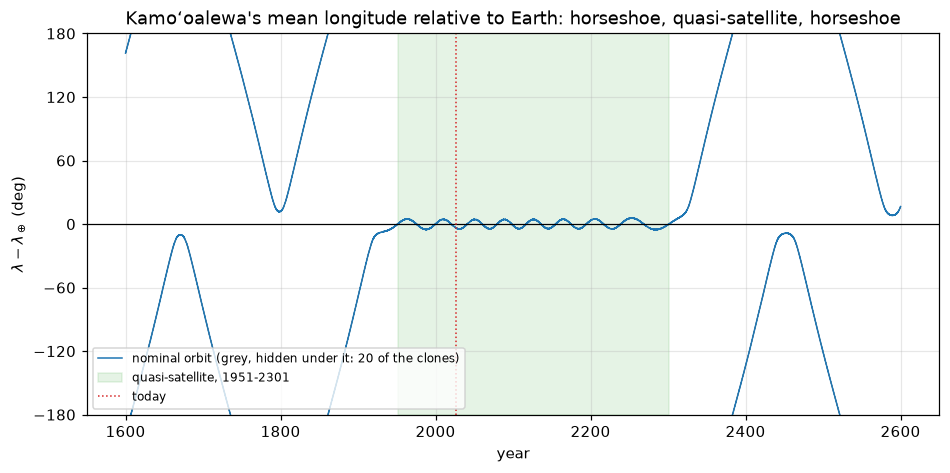

In [9]:
ens = pyroorb.sample_orbits(kamo, 100, rng_seed=1)
clones = ens.propagate(tdb(jd_long))                                  # (n_times, 100, 6)
lr_clones = np.array([relative_lambda(clones[:, j]) for j in range(clones.shape[1])])
episodes = np.array([qs_episode(lr) for lr in lr_clones])
k2400 = np.searchsorted(yr_long, 2400)
print(f"episode across 100 clones: start {episodes[:, 0].min():.0f}-{episodes[:, 0].max():.0f}, "
      f"end {episodes[:, 1].min():.0f}-{episodes[:, 1].max():.0f}")
print(f"lambda_r in 2400: nominal {lr_nom[k2400]:.3f} deg, clones +/- {lr_clones[:, k2400].std():.3f} deg, "
      f"without Yarkovsky {lr_noyark[k2400]:.3f} deg")

def broken(lr):                       # no vertical line where lambda_r wraps through +-180 deg
    out = lr.copy()
    out[1:][np.abs(np.diff(lr)) > 180] = np.nan
    return out

plt.figure(figsize=(10, 4.5))
for lr in lr_clones[:20]:
    plt.plot(yr_long, broken(lr), color="0.6", lw=0.4)
plt.plot(yr_long, broken(lr_nom), color="C0", lw=1, label="nominal orbit (grey, hidden under it: 20 of the clones)")
plt.axvspan(start, end, color="C2", alpha=0.12, label=f"quasi-satellite, {start:.0f}-{end:.0f}")
plt.axhline(0, color="k", lw=0.8)
plt.axvline(2026, color="C3", ls=":", lw=1, label="today")
plt.ylim(-180, 180); plt.yticks(range(-180, 181, 60))
plt.xlabel("year"); plt.ylabel(r"$\lambda - \lambda_\oplus$ (deg)")
plt.title("Kamoʻoalewa's mean longitude relative to Earth: horseshoe, quasi-satellite, horseshoe")
plt.legend(loc="lower left", fontsize=8); plt.show()

The present episode ends around 2300-2325 by either test. Its start depends on the
definition. $\lambda_r$ came within 15° of Earth around 1919, but its first sign change came
only around 1950. Through the 1920s-40s the guiding centre was still settling in on one side
of Earth. The looser definition matches de la Fuente Marcos & de la Fuente Marcos (2016) closely:
*"Its current quasi-satellite episode started nearly 100 yr ago and it will end in about 300 yr
from now"* (written in 2016, so about 1916 to 2316). The strict one gives a shorter episode,
about 1950-2300. Before and after, Kamoʻoalewa is in horseshoe
states. Each lasts a century or two, and each of its turning points (around 1670, 1800, 2450 and
2580) brings it back within about 10° of Earth, where a quasi-satellite stretch like the present
one can begin. The co-orbital pattern repeats.

**Is any of this uncertain?** Hardly, on these timescales. The 100 clones agree to a few
thousandths of a degree in 2400, and they all give the same episode dates. Switching off the
Yarkovsky force moves $\lambda_r$ by only about 0.02° by 2400. No close encounter with Earth
amplifies small differences (the asteroid never comes within 0.07 au over the whole
millennium, as printed above), so the orbit is predictable for centuries. Fenucci & Novaković
(2021) found that over *much* longer times the Yarkovsky drift can make Kamoʻoalewa leave
Earth's co-orbital region sooner than gravity alone would; a 1,000-year integration cannot test
that.

## 6. 2024 PT5: a two-month mini-moon

"Captured" here means the geocentric two-body energy
$\varepsilon = v^2/2 - GM_\oplus/r$ is negative, where $r$ and $v$ are the asteroid's position
and velocity relative to Earth's centre. This is the criterion the RNAAS note uses. We evaluate
it every 15 minutes through 2024, using PyRoOrb's fitted orbit and DE440's Earth.

In [10]:
GM_EARTH = 398600.435436 * 86400 ** 2 / AU_KM ** 3            # au^3/day^2 (DE440)
GM_MOON = 4902.800066 * 86400 ** 2 / AU_KM ** 3
GM_SUN = 1.32712440041e11 * 86400 ** 2 / AU_KM ** 3

jd = Time("2024-07-01").tdb.jd + np.arange(0, 240, 1 / 96)
P = pyroorb.propagate(pt5, tdb(jd))
E = pyroorb.body_states("earth", tdb(jd))
M = pyroorb.body_states("moon", tdb(jd))
geo = P - E
r = np.linalg.norm(geo[:, :3], axis=1)
energy = (geo[:, 3:] ** 2).sum(1) / 2 - GM_EARTH / r
energy_moon = energy - GM_MOON / np.linalg.norm(P[:, :3] - M[:, :3], axis=1)

def bound_interval(eps):
    i = np.flatnonzero(np.diff((eps < 0).astype(int)))
    return jd[i[0]], jd[i[1]]

t0, t1 = bound_interval(energy)
m0, m1 = bound_interval(energy_moon)
r_hill = np.linalg.norm(E[0, :3]) * (GM_EARTH / (3 * GM_SUN)) ** (1 / 3)
inside = (jd >= t0) & (jd <= t1)
print(f"geocentric energy < 0 : {utc(t0)} to {utc(t1)} UTC  ({t1 - t0:.1f} days)")
print(f"  ... Moon included   : {utc(m0)} to {utc(m1)} UTC  ({m1 - m0:.1f} days)")
print(f"published (RNAAS)     : 2024-09-29 to 2024-11-25  (56.6 days)")
print(f"distance at capture / release: {r[jd.searchsorted(t0)]:.4f} / {r[jd.searchsorted(t1)]:.4f} au; "
      f"while 'captured' {r[inside].min():.4f}-{r[inside].max():.4f} au; Earth's Hill radius {r_hill:.4f} au")

geocentric energy < 0 : 2024-09-29 19:45 to 2024-11-25 15:30 UTC  (56.8 days)
  ... Moon included   : 2024-09-29 13:30 to 2024-11-25 21:30 UTC  (57.3 days)
published (RNAAS)     : 2024-09-29 to 2024-11-25  (56.6 days)
distance at capture / release: 0.0232 / 0.0237 au; while 'captured' 0.0232-0.0270 au; Earth's Hill radius 0.0102 au


PyRoOrb finds exactly the published interval: September 29 to November 25, 2024, 56.8 days
against the paper's 56.6. The two-tenths-of-a-day difference is within what the choice of
criterion moves: adding the Moon's potential shifts the edges by a few hours, and the paper's
orbit came from the data available in September 2024, before most of the arc we fit.

There is a catch. During those two months 2024 PT5 was **outside Earth's Hill sphere**, about
2.3-2.7 Hill radii away. Its geocentric energy was slightly negative because it moved slowly relative to
Earth, not because Earth's gravity controlled it: the Sun's tide dominated throughout. It did
not complete a loop around Earth. This is why it was a "temporarily captured flyby" rather than
an orbiting mini-moon, and why some accounts said it was never really captured. The rotating
frame shows it:

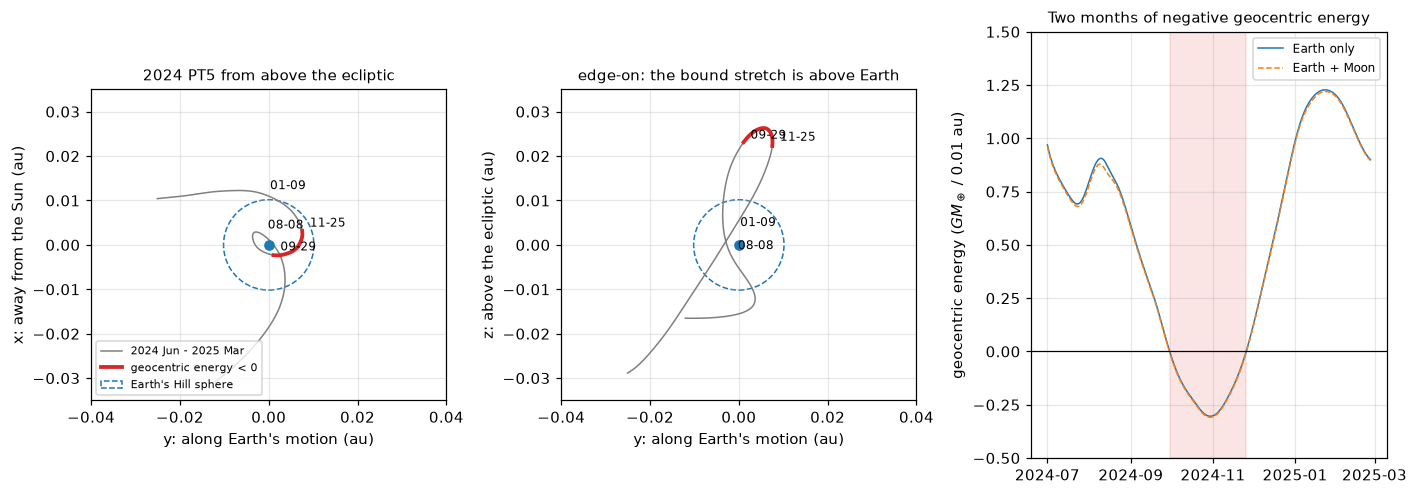

In [11]:
jd2 = Time("2024-06-01").tdb.jd + np.arange(0, 300, 0.25)
R2 = rotating(pyroorb.propagate(pt5, tdb(jd2)), pyroorb.body_states("earth", tdb(jd2)))
cap = (jd2 >= t0) & (jd2 <= t1)

fig, ax = plt.subplots(1, 3, figsize=(13, 4.6))
for axis, (j, lab) in zip(ax[:2], [(0, "x: away from the Sun (au)"), (2, "z: above the ecliptic (au)")]):
    axis.plot(R2[:, 1], R2[:, j], color="0.5", lw=1, label="2024 Jun - 2025 Mar")
    axis.plot(R2[cap, 1], R2[cap, j], color="C3", lw=2.5, label="geocentric energy < 0")
    axis.add_patch(plt.Circle((0, 0), r_hill, fill=False, ls="--", color="C0", label="Earth's Hill sphere"))
    axis.plot(0, 0, "o", color="C0", ms=6)
    for date in ["2024-08-08", "2024-09-29", "2024-11-25", "2025-01-09"]:
        i = np.searchsorted(jd2, Time(date).tdb.jd)
        axis.annotate(date[5:], (R2[i, 1], R2[i, j]), xytext=(5, 3), textcoords="offset points", fontsize=8)
    axis.set_aspect("equal"); axis.set_xlim(-0.04, 0.04); axis.set_ylim(-0.035, 0.035)
    axis.set_xlabel("y: along Earth's motion (au)"); axis.set_ylabel(lab)
ax[0].set_title("2024 PT5 from above the ecliptic", fontsize=10)
ax[1].set_title("edge-on: the bound stretch is above Earth", fontsize=10)
ax[0].legend(fontsize=7, loc="lower left")
ae = ax[2]
ae.plot(jd - jd[0], energy / GM_EARTH * 0.01, lw=1, label="Earth only")      # unit: GM_E / 0.01 au
ae.plot(jd - jd[0], energy_moon / GM_EARTH * 0.01, lw=1, ls="--", label="Earth + Moon")
ae.axhline(0, color="k", lw=0.8)
ae.axvspan(t0 - jd[0], t1 - jd[0], color="C3", alpha=0.12)
ticks = ["2024-07-01", "2024-09-01", "2024-11-01", "2025-01-01", "2025-03-01"]
ae.set_xticks([Time(t).tdb.jd - jd[0] for t in ticks], [t[:7] for t in ticks])
ae.set_ylabel(r"geocentric energy ($GM_\oplus$ / 0.01 au)")
ae.set_ylim(-0.5, 1.5); ae.legend(fontsize=8)
ae.set_title("Two months of negative geocentric energy", fontsize=10)
plt.tight_layout(); plt.show()

The asteroid passes Earth on August 8 (0.0038 au, inside the Hill sphere, but too fast to be
captured). Its energy is negative (red) during the slowest part of the encounter. Seen from above
the ecliptic, the red stretch looks close to Earth, but the edge-on view shows where it really
was: 0.02-0.026 au *above* the ecliptic. 2024 PT5's 1.7° inclination lifts it that far
above Earth's orbital plane at this phase. It comes back down, passes Earth again on January 9,
2025, and leaves.

**Close approaches against JPL's close-approach database (CAD).** CAD lists JPL's
close-approach predictions. We compare our times, distances and 1σ from `close_approaches`
(CAD's `dist_min`/`dist_max` bracket its 3σ range).

In [12]:
q = urllib.parse.urlencode({"des": "2024 PT5", "date-min": "2024-01-01", "date-max": "2060-01-01",
                            "dist-max": "0.05"})
cad = json.load(urllib.request.urlopen("https://ssd-api.jpl.nasa.gov/cad.api?" + q, timeout=60))
f = cad["fields"]
cad = [dict(zip(f, row)) for row in cad["data"]]
ours = pyroorb.close_approaches(pt5, "2024-07-01", "2060-01-01")
print(f"{'PyRoOrb (UTC)':18s}{'JPL CAD (TDB)':>19s}{'PyRoOrb au':>13s}{'1-sigma au':>12s}{'JPL au':>13s}"
      f"{'JPL 3-sigma':>13s}{'diff km':>9s}")
for c in ours:
    j = min(cad, key=lambda r: abs(float(r["jd"]) - c["jd_tdb"]))
    half = (float(j["dist_max"]) - float(j["dist_min"])) / 2
    print(f"{c['date_iso'][:16]:18s}{j['cd']:>19s}{c['distance_au']:13.7f}{c['sigma_distance_au']:12.1e}"
          f"{float(j['dist']):13.7f}{half:13.1e}{(c['distance_au'] - float(j['dist'])) * AU_KM:9.1f}")

PyRoOrb (UTC)           JPL CAD (TDB)   PyRoOrb au  1-sigma au       JPL au  JPL 3-sigma  diff km
2024-08-08 19:59    2024-Aug-08 20:00    0.0037897     2.0e-09    0.0037897      1.0e-08      0.1
2025-01-09 02:09    2025-Jan-09 02:11    0.0120360     6.1e-09    0.0120360      2.8e-08      0.0
2055-11-08 16:43    2055-Nov-08 16:43    0.0357786     1.9e-07    0.0357787      8.4e-07     -9.4


The 2024 and January 2025 encounters agree to well under a kilometre. 2024 PT5 returns to
Earth's neighbourhood in November 2055 (0.036 au, about 14 lunar distances). After 30 years the
two predictions still agree to about 10 km, a small fraction of either code's uncertainty.
The listed CAD times are TDB and ours UTC. The 69 s offset between the two scales is
invisible at CAD's one-minute rounding.

## Takeaways

* **From raw astrometry to Earth's companions in a few lines.** `fetch_observations` →
  `fit_orbit` → `propagate` + `body_states` is all it takes. Everything after that is numpy:
  the rotating frame, the mean longitudes, the geocentric energy.
* **Kamoʻoalewa earns a Yarkovsky term by itself.** `nongrav="auto"` keeps $A_2 \approx -1.34\times10^{-13}$
  au/day², which matches JPL's value well inside one σ and lowers the RMS by a quarter. The
  implied drift, about $-58\times10^{-4}$ au/Myr, is about 1.3σ weaker than Fenucci et al.'s
  (2025) $-67\times10^{-4}$, which uses astrometry not all in the MPC download.
* **The quasi-satellite is real and long-lived.** The fitted orbit traces the textbook yearly
  loop around Earth, 40-120 lunar distances away. Its relative mean longitude has stayed within
  15° of Earth since about 1919 and will until about 2325 (librating across 0° from about 1950 to
  2300), as de la Fuente Marcos & de la Fuente Marcos (2016) found: about 1916 to 2316. The clone cloud and the Yarkovsky force both move this by a
  negligible amount over centuries.
* **2024 PT5's capture dates are reproduced exactly.** Geocentric energy is negative from
  2024 September 29 to November 25, as published. But it was a loose capture, 2.3-2.7 Hill radii
  from Earth, with no orbit around us. Its 2055 return agrees with JPL's prediction to about 10 km.
* **Checks against JPL.** Geocentric distances agree to within 10 km inside the arcs and within
  our linear 1σ beyond them. The orbital planes differ by about 25 km at 1 au. For 2024 PT5
  that is more than either code's formal σ, most likely because the observation sets and
  weights differ.

**Caveats.** "Captured" follows the two-body energy criterion of the paper. A definition using
the Hill sphere or a full revolution around Earth would say 2024 PT5 was never captured. The
quasi-satellite's start date depends on how an episode is defined: the two tests here differ
by 30 years. The fits use the
planets, Moon and relativity (DE440) without the asteroid perturbers, which matter little for
these small, Earth-dominated orbits. The integrations cannot go past the 1550-2650 coverage of
the DE440 file. The physical nature of both objects (size, lunar origin) comes from the cited
papers, not from anything computed here.